<a href="https://colab.research.google.com/github/efitznm/Data-Science-Portfolio-C22/blob/main/Modules/Module_2_Regression/Projects/Instructions/Project.2-Housing/Housing-Pass-07.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 2 - Pass 07: Housing Price Prediction




The project should be done using Regression prediction techniques ( with feature scaling and regularization ) as covered in class.
The goal is to minimize the RMS ***percentage*** error ( root mean squared percentage error - RMSPE ) on your prediction of the house sales price.



Any of the available features can be used in the regression, but a minimum set of variables that do the job should be the ultimate goal.



Be sure to go through the whole data science process and document as such in your Jupyter notebook.



This project will have less direct "To Do" guidance and the progression through the data science process will be more individualized this time around.  We will talk about all the issues during class so you're not going to be out on a ledge with this one, I just want to move you towards performing a data science project on your own eventually.

There are two parts to this data set, both of which are on AWS:

- [Housing Data Dictionary]( https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Housing%20-%20Data%20Documentation.pdf )
- [Data Set]( https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv)


In [ ]:
! curl -s -I https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv

HTTP/1.1 200 OK
x-amz-id-2: SpStP9+UonajjzyMHc8AsCLlwPkYosRawWkXI1hF2mGaqTQ9jZazyvumN/gDF96jn21NVMFOuGzqRAqLR3jxYv73V+CnMN5o
x-amz-request-id: NW11BT8MN8Y73D55
Server: AmazonS3
Date: Tue, 27 Oct 2026 21:16:44 GMT
Last-Modified: Fri, 06 Oct 2023 04:00:27 GMT
ETag: "76e84c9ee7f6fd4d51276697f81e76e1"
x-amz-server-side-encryption: AES256
Accept-Ranges: bytes
Content-Length: 880420
Content-Type: text/csv



In [ ]:
! curl -s https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv | head -2

PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,Condition 2,Bldg Type,House Style,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Roof Style,Roof Matl,Exterior 1st,Exterior 2nd,Mas Vnr Type,Mas Vnr Area,Exter Qual,Exter Cond,Foundation,Bsmt Qual,Bsmt Cond,Bsmt Exposure,BsmtFin Type 1,BsmtFin SF 1,BsmtFin Type 2,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Heating,Heating QC,Central Air,Electrical,1st Flr SF,2nd Flr SF,Low Qual Fin SF,Gr Liv Area,Bsmt Full Bath,Bsmt Half Bath,Full Bath,Half Bath,Bedroom AbvGr,Kitchen AbvGr,Kitchen Qual,TotRms AbvGrd,Functional,Fireplaces,Fireplace Qu,Garage Type,Garage Yr Blt,Garage Finish,Garage Cars,Garage Area,Garage Qual,Garage Cond,Paved Drive,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
905101070,20,RL,62.0,14299,Pave,,Reg,Lvl,AllPub,Inside,G

## Problem Definition

### Business Problem

Target is *Sales Price* and feature is *all float features*

Help investors evaluate whether float features might be a useful factor when assessing a property's potential market value.

### Data Science Problem

Supervised regression

## Data Collection/Sources

### Load Modules

In [ ]:
# Import the libraries and modules
from IPython.display import Image

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns
import statsmodels.api as sm

from sklearn import datasets, metrics, model_selection
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler

### Load Data

In [ ]:
# Define the data's url as 'url'
url = 'https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv'    # insert url here
url

'https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv'

In [ ]:
# Define the data frame as 'df'
df = pd.read_csv(url)

## Data Cleaning

### Overview

In [ ]:
# Display the head - 81 columns
df.head()

,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,905101070,20,RL,62.0,14299,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,7,2007,WD,Normal,115400
1,905101330,90,RL,72.0,10791,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,Shed,500,10,2006,WD,Normal,90000
2,903454090,50,RM,50.0,9000,Pave,NaN,Reg,Bnk,AllPub,...,0,NaN,NaN,NaN,0,12,2007,WD,Normal,141000
3,533244030,60,FV,68.0,7379,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,254000
4,909252020,70,RL,60.0,7200,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,4,2009,WD,Normal,155000


In [ ]:
# Display the tail - target is the last row
df.tail()

,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
2632,903231070,50,RM,52.0,6240,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,Shed,400,9,2006,WD,Normal,114500
2633,906201021,80,RL,74.0,10778,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,7,2009,WD,Normal,162000
2634,533253070,120,RL,61.0,3782,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2009,WD,Normal,211500
2635,527376100,20,RL,78.0,10140,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,8,2009,WD,Normal,165000
2636,528292060,60,RL,41.0,12460,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2008,WD,Normal,225000


In [ ]:
# See the shape - 2637 rows, 81 columns
df.shape

(2637, 81)

In [ ]:
# See how many total entries
df.size

213597

### Summary Statistics

Summary statistics give you a quick overview of the data.  Some items to spot check:
- the Target:
  - look for nulls
    - null will be culled
  - look at min, max, median, and mean
    - is it a categorical field masquerading as a number?
- the Features:
  - numerical
    - look at min, max, median, and mean
      - a min=1 and max=count suggests an ID
  - categorical
    - look at unique and freq
      - freq=1, unique=count suggests an ID
      - freq=count suggests a meaningless feature

In [ ]:
# Summary meta-data - our target 'SalePrice' is int64, our feature 'Lot Frontage' is float64
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2637 entries, 0 to 2636
Data columns (total 81 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   PID              2637 non-null   int64  
 1   MS SubClass      2637 non-null   int64  
 2   MS Zoning        2637 non-null   object 
 3   Lot Frontage     2188 non-null   float64
 4   Lot Area         2637 non-null   int64  
 5   Street           2637 non-null   object 
 6   Alley            180 non-null    object 
 7   Lot Shape        2637 non-null   object 
 8   Land Contour     2637 non-null   object 
 9   Utilities        2637 non-null   object 
 10  Lot Config       2637 non-null   object 
 11  Land Slope       2637 non-null   object 
 12  Neighborhood     2637 non-null   object 
 13  Condition 1      2637 non-null   object 
 14  Condition 2      2637 non-null   object 
 15  Bldg Type        2637 non-null   object 
 16  House Style      2637 non-null   object 
 17  Overall Qual  

In [ ]:
# See the summary statistics
df.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
PID,2637.0,7.141301e+08,1.887527e+08,526301100.0,5.284770e+08,535453040.0,9.071870e+08,1.007100e+09
MS SubClass,2637.0,5.734926e+01,4.249909e+01,20.0,2.000000e+01,50.0,7.000000e+01,1.900000e+02
Lot Frontage,2188.0,6.916682e+01,2.335678e+01,21.0,5.800000e+01,68.0,8.000000e+01,3.130000e+02
Lot Area,2637.0,1.004469e+04,6.742550e+03,1300.0,7.436000e+03,9450.0,1.152600e+04,1.646600e+05
Overall Qual,2637.0,6.097459e+00,1.411522e+00,1.0,5.000000e+00,6.0,7.000000e+00,1.000000e+01
Overall Cond,2637.0,5.569966e+00,1.118262e+00,1.0,5.000000e+00,5.0,6.000000e+00,9.000000e+00
Year Built,2637.0,1.971289e+03,3.030699e+01,1872.0,1.954000e+03,1973.0,2.001000e+03,2.010000e+03
Year Remod/Add,2637.0,1.984203e+03,2.091308e+01,1950.0,1.965000e+03,1993.0,2.004000e+03,2.010000e+03
Mas Vnr Area,2614.0,1.018879e+02,1.795782e+02,0.0,0.000000e+00,0.0,1.640000e+02,1.600000e+03
BsmtFin SF 1,2636.0,4.384412e+02,4.496023e+02,0.0,0.000000e+00,368.0,7.320000e+02,5.644000e+03


### Target Nulls


The target should be the first field that you look at.  Its data type will tell you what kind of machine learning problem this is ( classification or regression. ) Any nulls should be culled.  You can check for any skew in the data set.

In [ ]:
# Define the name of the target column 'SalePrice' to work with it independently
target_col = 'SalePrice'
df[target_col]

,SalePrice
0,115400
1,90000
2,141000
3,254000
4,155000
...,...
2632,114500
2633,162000
2634,211500
2635,165000


In [ ]:
# Look for nulls in the target 'SalePrice' (dropping rows if 20% nulls or under) - no nulls in the target
df[target_col].isnull().sum() / df[target_col].shape[0] * 100


np.float64(0.0)

### Feature Nulls

In [ ]:
# Define the name of the feature column 'Lot Frontage' to work with it independently
feature_col = 'Lot Frontage'
df[feature_col]

,Lot Frontage
0,62.0
1,72.0
2,50.0
3,68.0
4,60.0
...,...
2632,52.0
2633,74.0
2634,61.0
2635,78.0


In [ ]:
# Look for nulls in the feature 'Lot Frontage' (dropping rows if 20% nulls or under) - 17% are nulls
df[feature_col].isnull().sum() / df[feature_col].shape[0] * 100

np.float64(17.02692453545696)

### Identifier Columns

In [ ]:
# See proportion of unique values in the target column
(df[target_col].nunique() / df[target_col].shape[0] * 100) #.sort_values(ascending=False)

37.2772089495639

In [ ]:
# See proportion of unique values in the feature column
(df[feature_col].nunique() / df[feature_col].shape[0] * 100)

4.778156996587031

In [ ]:
# See for all data - PID is an identifier column
(df.nunique() / df.shape[0] * 100).sort_values(ascending=False)

,0
PID,100.000000
Lot Area,68.221464
Gr Liv Area,46.113007
Bsmt Unf SF,40.955631
1st Flr SF,38.756162
...,...
Bsmt Half Bath,0.113766
Paved Drive,0.113766
Street,0.075844
Alley,0.075844


In [ ]:
# See the data types of our target and feature - continuous are good for linear regression
df[[target_col, feature_col]].dtypes

,0
SalePrice,int64
Lot Frontage,float64


### Backup #1

In [ ]:
# Make a backup
df_bak1 = df.copy()

In [ ]:
# Restore from backup
df = df_bak1.copy()

### Cull the Nulls

Feature column containing 17% nulls, so drop those rows in our dataset.

In [ ]:
# Drop null rows referencing the feature column
df = df.dropna(subset=feature_col)

In [ ]:
# Verify rows dropped
df.shape

(2188, 81)

### Backup #2

In [ ]:
# Make a backup
df_bak2 = df.copy()

In [ ]:
# Restore from backup
df = df_bak2.copy()

### Working Data Frame

In [ ]:
# Define our target and feature columns as a data frame to work with 'iso_df'
clean_df = df[[target_col, feature_col]].reset_index(drop=True)

In [ ]:
# Verify the working data frame
clean_df

,SalePrice,Lot Frontage
0,115400,62.0
1,90000,72.0
2,141000,50.0
3,254000,68.0
4,155000,60.0
...,...,...
2183,114500,52.0
2184,162000,74.0
2185,211500,61.0
2186,165000,78.0


## EDA (Exploratory Data Analysis)

### Linear Regression Check

Linear Regression has two requirements:
1. the features are correlated with the target
1. the features are not correlated with each other

#### Correlation with Target

In [ ]:
# Calculate a correlation matrix for the target
corr_mat = clean_df.corr()
corr_mat

,SalePrice,Lot Frontage
SalePrice,1.000000,0.357142
Lot Frontage,0.357142,1.000000


##### Correlation matrix

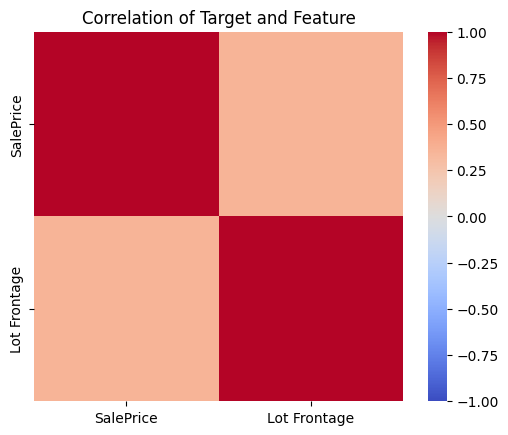

In [ ]:
# Display the correlation matrix - check if feature correlated with the target
sns.heatmap(
    corr_mat,
    square=True,
    annot=False,
    fmt='d',
    cbar=True,
    cmap='coolwarm',
    vmin=-1,vmax=1
)

plt.title('Correlation of Target and Feature');

Feature is highly correclated with the target.

##### Correlation Ranking
Ranking doesn't make sense for a single feature.

In [ ]:
# Create a data series with features ranked by correlation


### Independence of Features
Doesn't make sense for a single feature.

In [ ]:
# Calculate a correlation matrix for the features


In [ ]:
# Display the correlation matrix


In [ ]:
# Create a data series with features ranked by correlation


## Data Processing

Prepare Data Frame (Target and Features)

In [ ]:
# Define out the target and feature columns from our cleaned working data frame
target_col_clean = 'SalePrice'
feature_col_clean = 'Lot Frontage'

#### Performance

##### Linear Regression

Multi Cross Validation

In [ ]:
# Multiple CV loop
n = 100
results = np.zeros(n)

for i in range(n):
    X_train, X_test, y_train, y_test = train_test_split(
        clean_df[[feature_col_clean]],
        clean_df[[target_col_clean]],
        test_size=0.25,
        random_state=None
    )

    # Create an empty LR model
    modelLR = LinearRegression()

    # Train ( fit ) the model
    modelLR.fit( (X_train), y_train)

    # Make predicitons using the model
    pred_results = modelLR.predict(X_test)

    # calculate the accuracy
    results[i] = metrics.r2_score(y_test, pred_results)

results

array([0.16867302, 0.1234916 , 0.11420616, 0.09887689, 0.156713  ,
       0.11488974, 0.11017983, 0.10053526, 0.07293031, 0.11006556,
       0.15073548, 0.12006588, 0.10230178, 0.1419955 , 0.15389736,
       0.14657643, 0.17322556, 0.15918457, 0.14527922, 0.15883241,
       0.18335162, 0.09491195, 0.15216539, 0.12082143, 0.14320658,
       0.14356112, 0.09604475, 0.08958006, 0.14151195, 0.13541958,
       0.12502212, 0.18103554, 0.09748976, 0.12693779, 0.09698506,
       0.14410956, 0.11344328, 0.15613679, 0.10484656, 0.11866474,
       0.12678731, 0.10336526, 0.14829231, 0.16965314, 0.15133616,
       0.12598353, 0.10080575, 0.13563915, 0.12707949, 0.1346096 ,
       0.15604574, 0.12603086, 0.09014642, 0.1297169 , 0.11559807,
       0.1410582 , 0.10531699, 0.14994775, 0.15375899, 0.12588842,
       0.14675434, 0.12453453, 0.12367694, 0.12154307, 0.12702747,
       0.15972521, 0.04119072, 0.15923149, 0.10913261, 0.07100436,
       0.16623609, 0.14667848, 0.16666825, 0.13451885, 0.16391

''

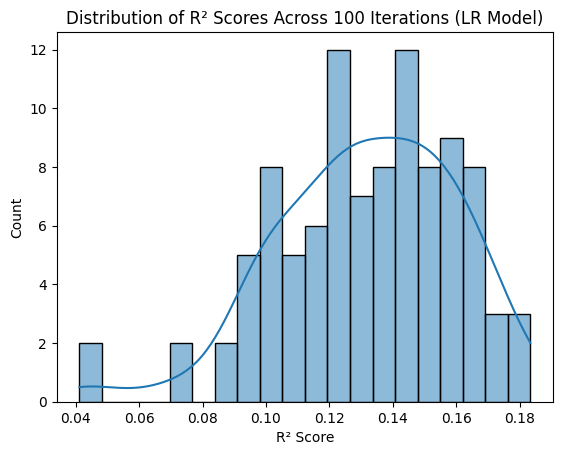

In [ ]:
# Display a histogram of the multi CV results
sns.histplot(results, kde=True, bins=20)
plt.title('Distribution of R² Scores Across 100 Iterations (LR Model)')
plt.xlabel('R² Score')
plt.ylabel('Count')
;

In [ ]:
# Linear Regression - prediction peformance stats
print("Mean R²:", np.mean(results))
print("Standard deviation:", np.std(results))
print("Minimum R²:", np.min(results))
print("Maximum R²:", np.max(results))

Mean R²: 0.13153421855348776
Standard deviation: 0.02789982174029596
Minimum R²: 0.041190716082937895
Maximum R²: 0.18335162128415095


##### Lasso Regression (Regularization)

In [ ]:
# Define X and y as feature and target columns
X = clean_df[[feature_col_clean]]
y = clean_df[[target_col_clean]]

# normalize the features
scaler = StandardScaler()
scaler.fit_transform(X)


array([[-0.30691121],
       [ 0.12132788],
       [-0.82079811],
       ...,
       [-0.34973511],
       [ 0.37827134],
       [-1.20621329]])

In [ ]:
# Verify columns in X (feature)
X.columns


Index(['Lot Frontage'], dtype='object')

In [ ]:
# Define X_scaled
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size = 0.2, random_state=5)


Multi Cross Validation

In [ ]:
# Specify values of alpha we want to try
alpha = [1e-15, 1e-10, 1e-8, 1e-4, 1e-3, 1e-2, 1e-1, 1, 2, 3, 4, 5, 10, 20, 30, 50]

# Create empty list to hold results
results_alpha = []

for a in alpha:
  # Train the model
  my_fit_lasso = Lasso(alpha = a, tol = .01, max_iter=100_000) # Looping through alpha
  my_fit_lasso.fit(X_train, y_train)

  # Calculate CV RMSE
  results = cross_val_score(
      my_fit_lasso,
      X_scaled,
      y,
      scoring='neg_root_mean_squared_error',
      cv = 10
  )
  rmse = abs(results.mean())
  results_alpha.append(rmse)

results_df = pd.DataFrame({'Alpha': alpha, 'RMSE': results_alpha})
print(results_df.sort_values(by=['RMSE']))

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 5.049e+12, tolerance: 1.170e+11
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 5.793e+12, tolerance: 1.324e+11
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 5.714e+12, tolerance: 1.303e

           Alpha          RMSE
15  5.000000e+01  76595.290175
14  3.000000e+01  76595.484419
13  2.000000e+01  76595.583486
12  1.000000e+01  76595.683850
11  5.000000e+00  76595.734518
10  4.000000e+00  76595.744690
9   3.000000e+00  76595.754876
8   2.000000e+00  76595.765074
7   1.000000e+00  76595.775286
6   1.000000e-01  76595.784487
5   1.000000e-02  76595.785408
4   1.000000e-03  76595.785500
3   1.000000e-04  76595.785509
2   1.000000e-08  76595.785510
1   1.000000e-10  76595.785510
0   1.000000e-15  76595.785510


<Axes: >

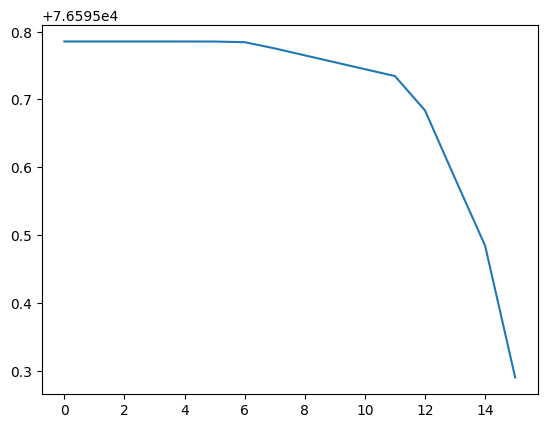

In [ ]:
results_df.sort_values( by = ["Alpha"])["RMSE"].plot()

Alpha of 50 gives us the lowest RMSE score.

In [ ]:
# Retrain the model w/ alpha = 50
my_fit_rr = Ridge(alpha = 50)
my_fit_rr.fit(X_train, y_train)

# Calculate CV RMSE
results = cross_val_score(my_fit_rr, X_scaled, y, scoring='neg_root_mean_squared_error', cv = 10)
rmse = abs(results.mean())
print(f"CV RMSE: {rmse}")

CV RMSE: 76584.65142803648


In [ ]:
# Multiple CV loop for Ridge with alpha=50.
n = 100
results = np.zeros(n)

for i in range(n):
    X_train, X_test, y_train, y_test = train_test_split(
        clean_df[[feature_col_clean]],
        clean_df[[target_col_clean]],
        test_size=0.25,
        random_state=None
    )

    # Create an empty LR model
    my_fit_rr = Ridge(alpha = 50)

    # Train ( fit ) the model
    my_fit_rr.fit(X_train, y_train)

    # Make predicitons using the model
    pred_results = my_fit_rr.predict(X_test)

    # calculate the accuracy
    results[i] = metrics.r2_score(y_test, pred_results)

results

array([0.14762775, 0.18798194, 0.14383355, 0.08176549, 0.08956809,
       0.10504083, 0.13085154, 0.09015697, 0.09389546, 0.108778  ,
       0.14905798, 0.08384757, 0.12051427, 0.14512756, 0.13511599,
       0.14703524, 0.13336485, 0.01354115, 0.14949639, 0.11286613,
       0.13956848, 0.09221359, 0.10946759, 0.10073286, 0.10222313,
       0.16463134, 0.12241651, 0.09053891, 0.02424475, 0.1037028 ,
       0.18080158, 0.15278291, 0.11777227, 0.1583339 , 0.16404217,
       0.13456951, 0.13344619, 0.16848273, 0.10327283, 0.07387379,
       0.13192929, 0.09184054, 0.09289552, 0.16332697, 0.07955061,
       0.10745842, 0.13642077, 0.15338659, 0.05159639, 0.12858963,
       0.09674304, 0.15416867, 0.09448189, 0.15726946, 0.13649318,
       0.13226554, 0.14499   , 0.08756996, 0.12046227, 0.1356519 ,
       0.1145925 , 0.12556917, 0.14419092, 0.10302162, 0.15282107,
       0.12245501, 0.13897915, 0.04517965, 0.16470367, 0.10210522,
       0.13583895, 0.13996492, 0.07301887, 0.11942067, 0.12173

''

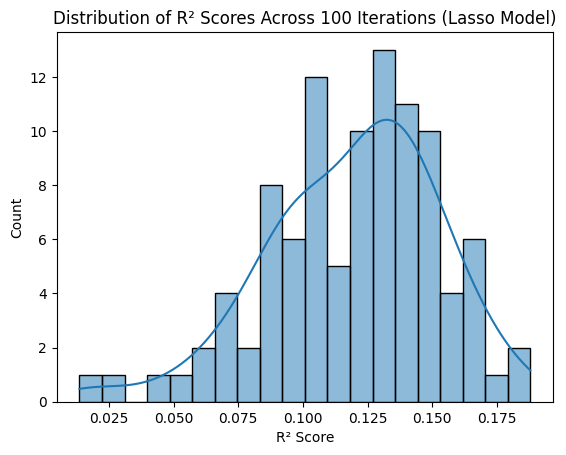

In [ ]:
# Display a histogram of the multi CV results for Ridge with alpha=50.
sns.histplot(results, kde=True, bins=20)
plt.title('Distribution of R² Scores Across 100 Iterations (Lasso Model)')
plt.xlabel('R² Score')
plt.ylabel('Count')
;

## Data Visualization

#### Actual vs. Predicted

#### Residual Analysis

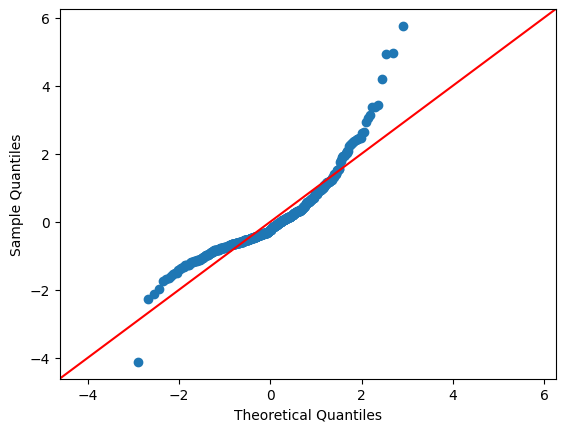

In [ ]:
# QQ Plot - Residuals are not normally distributed
res = y_test['SalePrice'] - pred_results
sm.qqplot(res, fit=True, line="45") ;

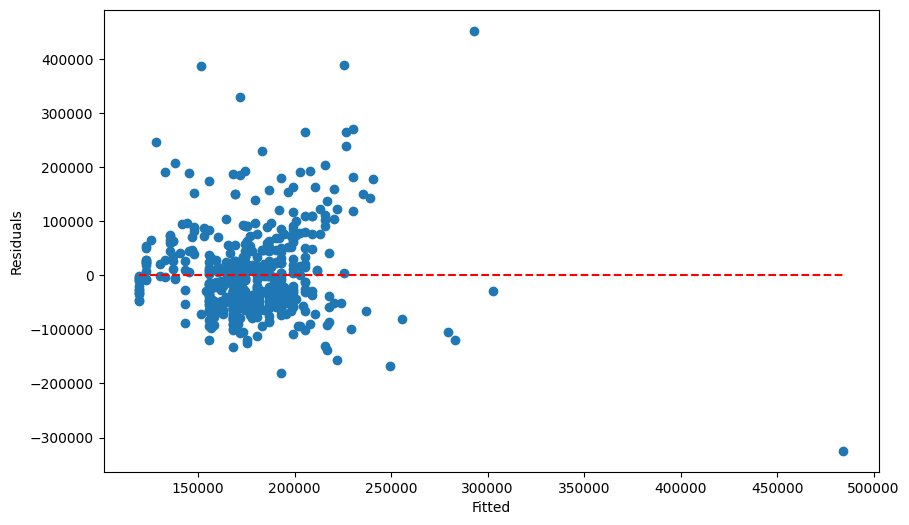

In [ ]:
# Residuals vs Fitted (Predicted) Values - Constant variance
plt.figure(figsize = (10,6))
plt.scatter(pred_results, res)
plt.xlabel("Fitted")
plt.ylabel("Residuals")
plt.hlines(0, min(pred_results), max(pred_results), colors = 'red', linestyles = 'dashed') ;

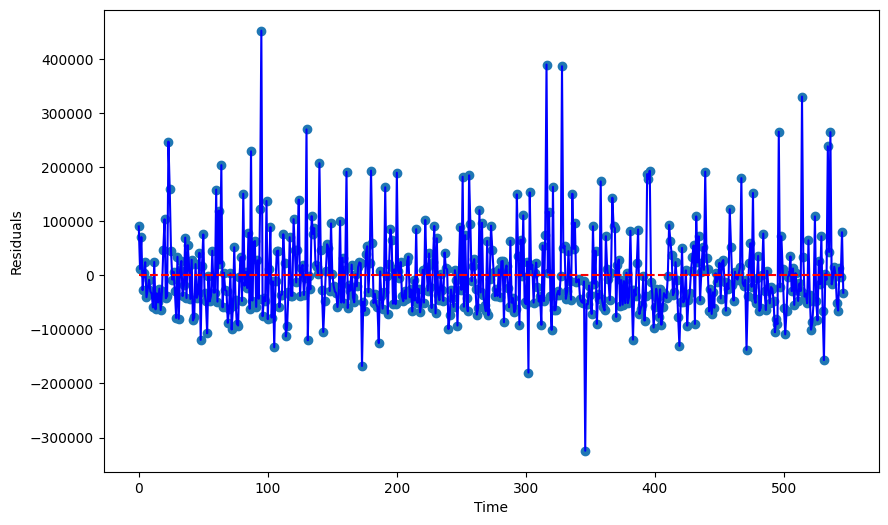

In [ ]:
# Residuals vs Time - indepedence
plt.figure(figsize = (10,6))
plt.scatter(range(len(res)), res)
plt.plot(range(len(res)), res, 'b')
plt.xlabel("Time")
plt.ylabel("Residuals")
plt.hlines(0, min(range(len(res))), max(range(len(res))), colors = 'red', linestyles = 'dashed') ;

In [ ]:
# Ridge Regression with alpha=50 - prediction peformance stats
print("Mean R²:", np.mean(results))
print("Standard deviation:", np.std(results))
print("Minimum R²:", np.min(results))
print("Maximum R²:", np.max(results))

Mean R²: 0.11936381080727371
Standard deviation: 0.03280758612091701
Minimum R²: 0.013541150050376816
Maximum R²: 0.18798193749245906


## Communication of Results

#### Conclusion

Mean R² for Linear Regression Model: 0.13153421855348776

Mean R² for Lasso Regression (alpha=50): 0.11936381080727371

Lasso regerssion performed slightly better than Linear Regression. Residuals should have a more normal distribution.

#### Future Work
- Try a different model
- Try additional features